# 📈 Maya Shows the Data: Day 2 Practical
### Week 2 · Visualising with Matplotlib and Seaborn

Maya's table is correct, but nobody at the district meeting will read 840 rows. Today you'll build the charts, then **one page that makes her case in seconds**.

**How to use this notebook**
- Keep this notebook and **clinic_visits_clean.csv** in the same folder.
- Press **Shift + Enter** to run a cell, and run the steps **in order**: later steps reuse earlier variables.
- Compare your chart with the ✅ *expected chart*.
- Muddled? Use **Kernel → Restart & Run All**.

> 🔒 All data in this notebook is made up.

---
## Step 1 · Load the clean data and draw your first line  *(~5 min)*
**Concept:** import matplotlib.pyplot as plt, plt.plot, plt.show

📖 The district meeting is on Friday. Maya's table is correct, but nobody in the room will read 840 rows. Let's start with malaria through the year.

🎯 **Your task**
1. Import the three libraries and load the data.
2. Count malaria visits per month.
3. Draw the line. It works, but what's missing?

<details><summary>👀 Need the code? Click to reveal (try on your own first!)</summary>

```python
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("clinic_visits_clean.csv")
malaria = df[df["diagnosis"] == "Malaria"]
by_month = malaria.groupby("month")["visit_id"].count()

plt.plot(by_month.index, by_month.values)
plt.show()
```
</details>

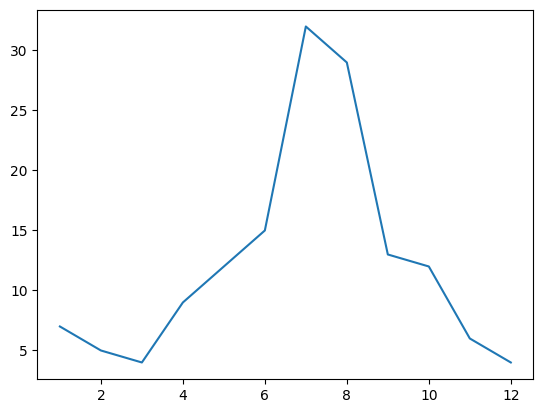

In [5]:
# Step 1: imports, load the data, first line chart
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\HP\Documents\DS.E1x\Beginner_Data_Science_Course\Week_02_Pandas_and_Visualisation\clinic_visits_clean.csv")
malaria = df[df['diagnosis'] == 'Malaria']
by_month = malaria.groupby('month')['visit_id'].count()
plt.plot(by_month.index, by_month.values)
plt.show()

✅ **Expected chart**

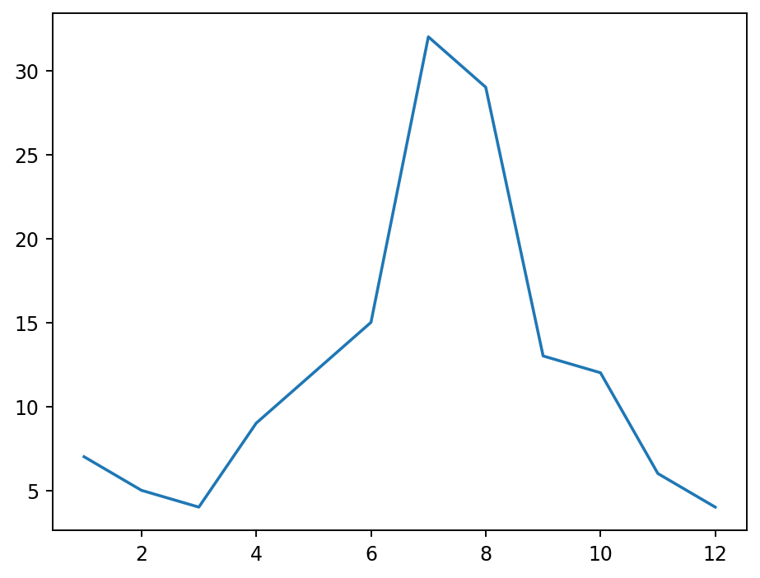

💡 plt.plot(x, y) takes the positions along the bottom, then the heights. The chart has no title and no axis names, so nobody can tell what it's about yet.

🆘 *If you see* `FileNotFoundError: clinic_visits_clean.csv` → Put the CSV in the same folder as this notebook.

---
## Step 2 · Make it readable  *(~5 min)*
**Concept:** figsize, color, marker, title, labels, ylim

📖 A chart without labels is like a thermometer without numbers. Maya gives this one a title that says what the chart found.

🎯 **Your task**
1. Redraw the line with a size, a colour and markers.
2. Add a title, axis labels and all 12 month ticks.
3. Start the y-axis at 0 with `plt.ylim(0)`.

<details><summary>👀 Need the code? Click to reveal (try on your own first!)</summary>

```python
plt.figure(figsize=(8, 4))
plt.plot(by_month.index, by_month.values, color="#D9533D", linewidth=2.5, marker="o")
plt.title("Malaria visits peak in July and August")
plt.xlabel("Month of 2025")
plt.ylabel("Malaria visits")
plt.xticks(range(1, 13))
plt.ylim(0)
plt.show()
```
</details>

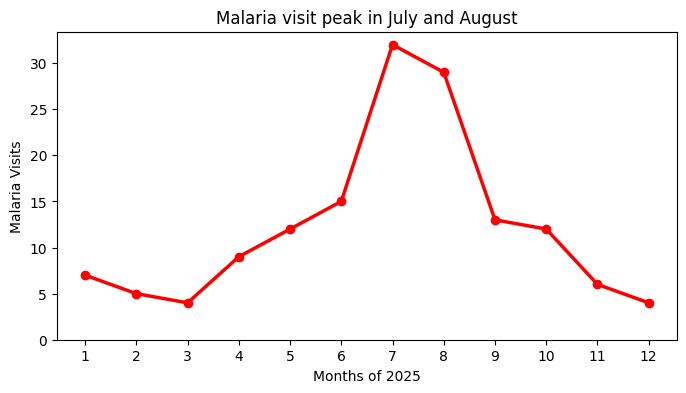

In [9]:
# Step 2: make the line chart readable
plt.figure(figsize=(8, 4))
plt.plot(by_month.index, by_month.values, color='red', linewidth=2.5, marker='o')
plt.title('Malaria visit peak in July and August')
plt.xlabel('Months of 2025')
plt.ylabel('Malaria Visits')
plt.xticks(range(1, 13))
plt.ylim(0)
plt.savefig('malaria_report.png')
plt.show()

✅ **Expected chart**

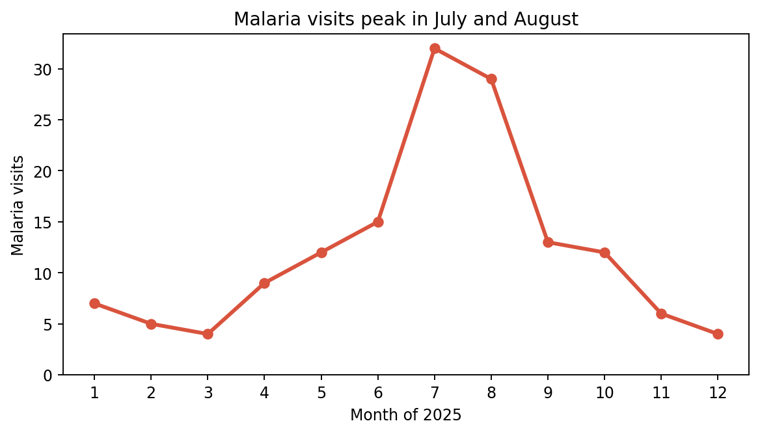

💡 The title states the finding, not just the topic. Compare it with 'Malaria by month': one tells you the answer, the other makes you hunt for it.

🆘 *If you see* `TypeError: 'str' object is not callable` → You wrote plt.title = "..." somewhere. Restart the kernel and use plt.title("...") with brackets.

---
## Step 3 · Compare wards with a bar chart  *(~5 min)*
**Concept:** plt.barh, sorting

📖 Kofi wants to see which ward handles the most visits. Comparing categories is a job for bars.

🎯 **Your task**
1. Count the visits per ward and sort them.
2. Draw horizontal bars.
3. Change `sort_values()` to `sort_index()`. Which version is easier to read?

<details><summary>👀 Need the code? Click to reveal (try on your own first!)</summary>

```python
by_ward = df["ward"].value_counts().sort_values()

plt.figure(figsize=(8, 3.5))
plt.barh(by_ward.index, by_ward.values, color="#2F79B5")
plt.title("Outpatients sees more visits than any other ward")
plt.xlabel("Visits in the 2025 sample")
plt.show()
```
</details>

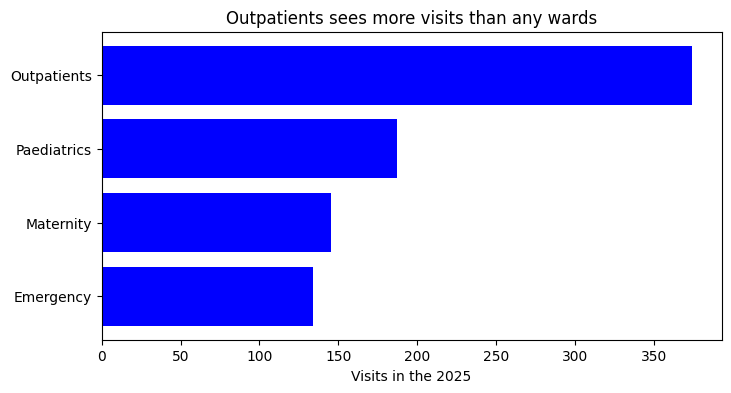

In [19]:
# Step 3: bar chart of visits per ward
by_ward = df['ward'].value_counts().sort_values()

plt.figure(figsize=(8, 4))
plt.barh(by_ward.index, by_ward.values, color='blue')
plt.title('Outpatients sees more visits than any wards')
plt.xlabel('Visits in the 2025')
plt.show()

✅ **Expected chart**

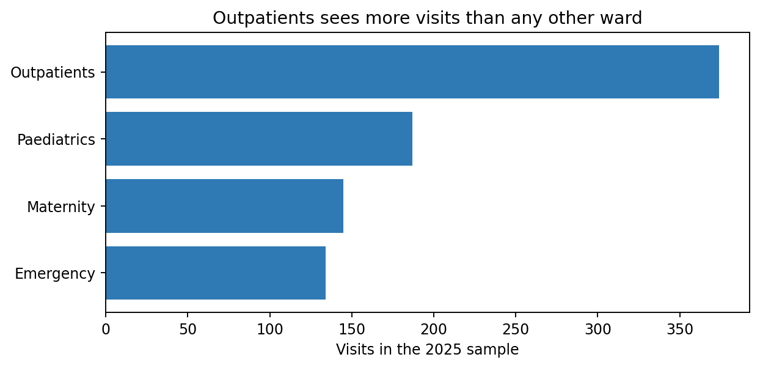

💡 Sorted bars let the eye jump straight to the biggest and smallest. Horizontal bars also give long labels room to breathe.

🆘 *If you see* `ValueError: shape mismatch` → Your x and y have different lengths. Use by_ward.index and by_ward.values from the same variable.

---
## Step 4 · See the spread with a histogram  *(~5 min)*
**Concept:** plt.hist, bins, plt.axvline

📖 An average of about 40 minutes hides a lot. Some people wait 5 minutes and some wait far longer. A histogram shows everyone at once.

🎯 **Your task**
1. Draw a histogram of `wait_mins` with 20 bins.
2. Add a dashed line at the mean.
3. Try `bins=5` and `bins=60`. What changes?

<details><summary>👀 Need the code? Click to reveal (try on your own first!)</summary>

```python
mean_wait = df["wait_mins"].mean()

plt.figure(figsize=(8, 4))
plt.hist(df["wait_mins"], bins=20, color="#23876A", edgecolor="white")
plt.axvline(mean_wait, color="#2F2A3B", linestyle="--", label=f"Mean: {mean_wait:.0f} min")
plt.title("Most waits are under an hour, but a long tail runs past 100 minutes")
plt.xlabel("Waiting time (minutes)")
plt.ylabel("Number of visits")
plt.legend()
plt.show()
```
</details>

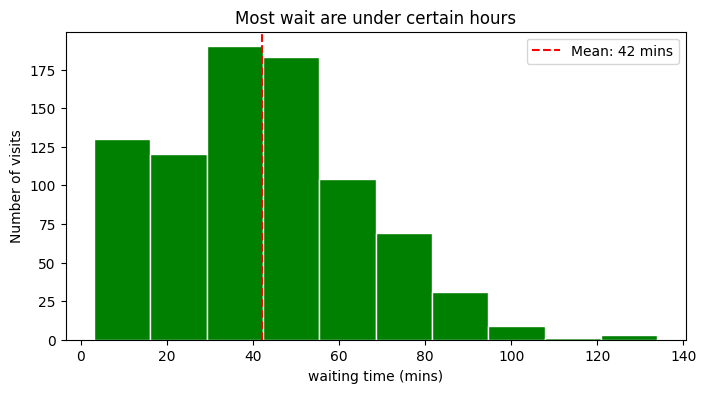

In [31]:
# Step 4: histogram of waiting times
mean_wait = df['wait_mins'].mean()
plt.figure(figsize=(8, 4 ))
plt.hist(df['wait_mins'], bins=10, color='green', edgecolor='white')
plt.axvline(mean_wait, color='red', linestyle='--', label=f'Mean: {mean_wait:.0f} mins')
plt.title('Most wait are under certain hours')
plt.xlabel('waiting time (mins)')
plt.ylabel('Number of visits')
plt.legend()
plt.show()

✅ **Expected chart**

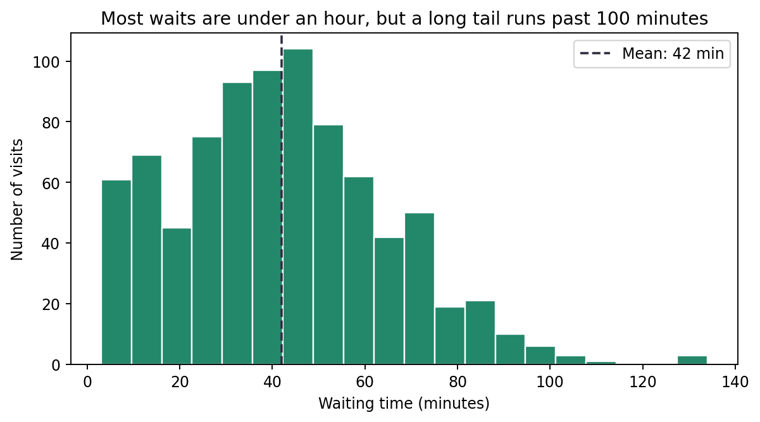

💡 A bin is a bucket, like '20 to 30 minutes'. Each bar counts how many visits fell in that bucket. Too few bins hides the shape and too many makes it noisy.

🆘 *If you see* `ValueError: could not convert string to float` → You passed a text column. Histograms need numbers.

---
## Step 5 · Find a relationship with a scatter plot  *(~4 min)*
**Concept:** plt.scatter, alpha

📖 Do taller patients weigh more? One dot per visit answers that at a glance.

🎯 **Your task**
1. Plot height against weight.
2. Set `alpha=0.5` so that overlapping dots show up darker.
3. Remove `alpha` and compare the two.

<details><summary>👀 Need the code? Click to reveal (try on your own first!)</summary>

```python
plt.figure(figsize=(6, 4))
plt.scatter(df["height_m"], df["weight_kg"], s=18, alpha=0.5, color="#6A4FA3")
plt.title("Taller patients tend to weigh more")
plt.xlabel("Height (m)")
plt.ylabel("Weight (kg)")
plt.show()
```
</details>

In [ ]:
# Step 5: scatter plot


✅ **Expected chart**

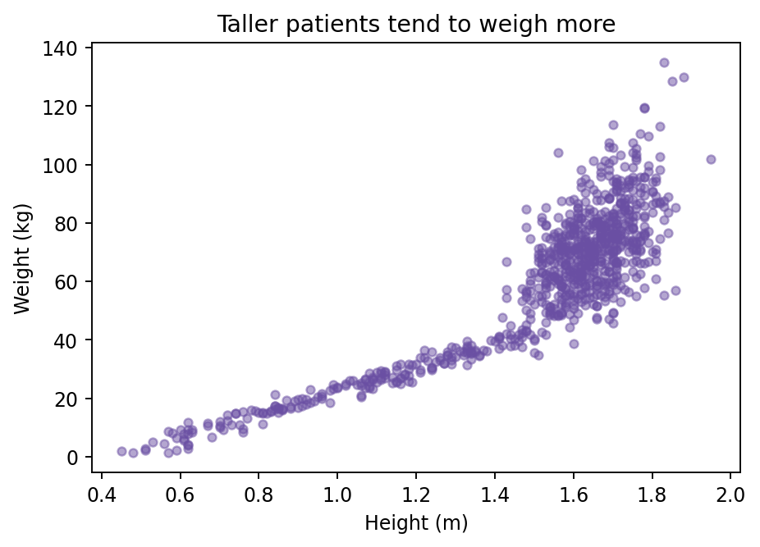

💡 A scatter plot shows the relationship between two number columns. Rows with a missing weight are left out automatically.

🆘 *If you see* `ValueError: x and y must be the same size` → Use two columns from the same DataFrame.

---
## Step 6 · Two charts side by side  *(~5 min)*
**Concept:** fig, ax = plt.subplots, ax.set_title

📖 One figure can hold several charts. Think of a figure as the page and each ax as one chart on that page.

🎯 **Your task**
1. Create a figure with 1 row and 2 charts.
2. Draw on `axes[0]` and `axes[1]`.
3. Change `(1, 2)` to `(2, 1)` and adjust the figsize.

<details><summary>👀 Need the code? Click to reveal (try on your own first!)</summary>

```python
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

axes[0].barh(by_ward.index, by_ward.values, color="#2F79B5")
axes[0].set_title("Visits per ward")

axes[1].hist(df["wait_mins"], bins=20, color="#23876A", edgecolor="white")
axes[1].set_title("Waiting time (minutes)")

plt.tight_layout()
plt.show()
```
</details>

In [ ]:
# Step 6: two charts in one figure


✅ **Expected chart**

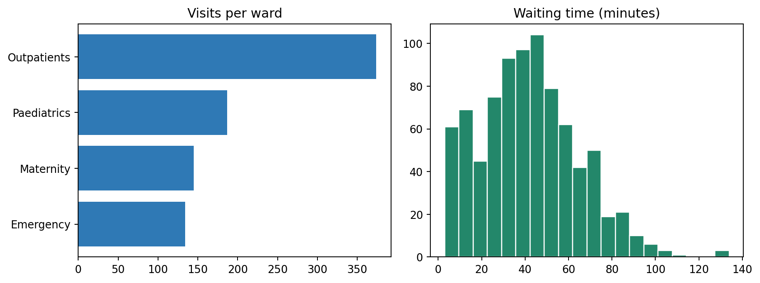

💡 On an ax, most commands gain set_: plt.title becomes ax.set_title and plt.xlabel becomes ax.set_xlabel. tight_layout() stops the charts bumping into each other.

🆘 *If you see* `AttributeError: 'Axes' object has no attribute 'title'` → On an ax, use ax.set_title("...").

---
## Step 7 · Seaborn: counts and box plots in one line  *(~6 min)*
**Concept:** sns.countplot, sns.boxplot, data= x= y=

📖 Seaborn sits on top of Matplotlib. You give it the table and the column names, and it does the counting and the grouping for you.

🎯 **Your task**
1. Count the diagnoses with `sns.countplot`.
2. Compare temperature across diagnoses with `sns.boxplot`.
3. Which diagnoses sit above the 37.5°C fever line?

<details><summary>👀 Need the code? Click to reveal (try on your own first!)</summary>

```python
order = df["diagnosis"].value_counts().index

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

sns.countplot(data=df, y="diagnosis", order=order, color="#2F79B5", ax=axes[0])
axes[0].set_title("Respiratory infection and malaria lead")
axes[0].set_xlabel("Visits")
axes[0].set_ylabel("")

sns.boxplot(data=df, y="diagnosis", x="temp_c", order=order, color="#FFCB52", ax=axes[1])
axes[1].axvline(37.5, color="#D9533D", linestyle="--")
axes[1].set_title("Malaria runs hottest (dashed line = 37.5°C fever)")
axes[1].set_xlabel("Temperature (°C)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()
```
</details>

In [ ]:
# Step 7: Seaborn countplot and boxplot


✅ **Expected chart**

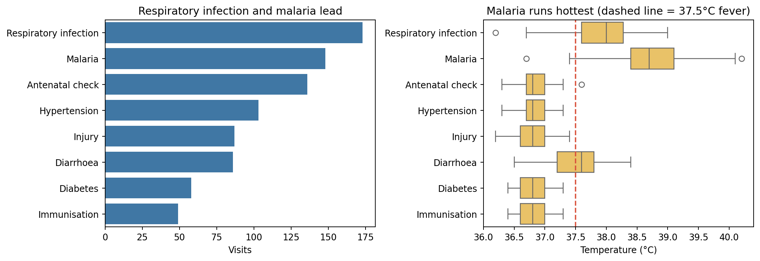

💡 The box holds the middle half of patients, the line inside is the median, and dots are unusual values. Seaborn draws onto any ax you pass with ax=.

🆘 *If you see* `ValueError: Could not interpret value `temp` for `x`` → The column is temp_c. Seaborn needs the exact column name.

---
## Step 8 · Split a line by group with hue  *(~5 min)*
**Concept:** sns.lineplot, hue, reset_index

📖 Is malaria the only illness that follows the rains? Let's put it next to respiratory infections.

🎯 **Your task**
1. Make a tidy table of visits per month and diagnosis.
2. Draw it with `hue="diagnosis"`.
3. Add "Diarrhoea" to the list and run it again.

<details><summary>👀 Need the code? Click to reveal (try on your own first!)</summary>

```python
two = df[df["diagnosis"].isin(["Malaria", "Respiratory infection"])]
counts = two.groupby(["month", "diagnosis"])["visit_id"].count().reset_index(name="visits")

plt.figure(figsize=(8, 4))
sns.lineplot(data=counts, x="month", y="visits", hue="diagnosis", marker="o", linewidth=2.5,
             palette=["#D9533D", "#2F79B5"])
plt.title("Malaria surges in July and August while respiratory visits dip")
plt.xlabel("Month of 2025")
plt.ylabel("Visits")
plt.xticks(range(1, 13))
plt.ylim(0)
plt.legend(title="")
plt.show()
```
</details>

In [ ]:
# Step 8: one line per diagnosis


✅ **Expected chart**

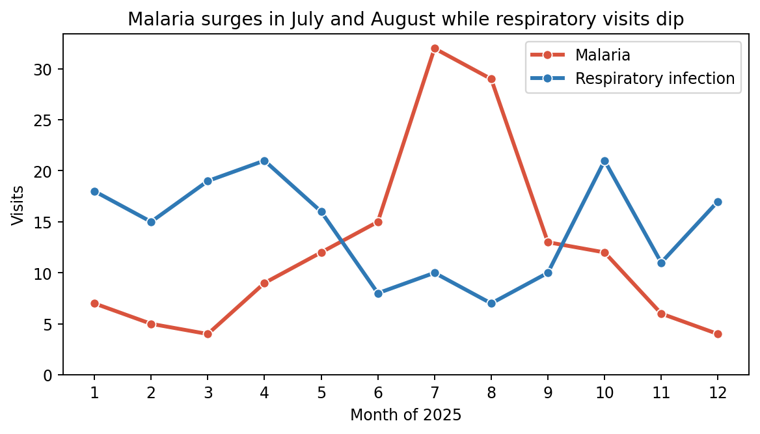

💡 hue means 'give each group its own colour'. Seaborn draws one line per group and adds the legend for you.

🆘 *If you see* `ValueError: The palette list has the wrong number of colors` → If you add a third diagnosis, add a third colour too, or remove palette=.

---
## Step 9 · Spot the bottleneck with a heatmap  *(~5 min)*
**Concept:** pivot_table, .reindex, sns.heatmap

📖 Maya suspects Mondays are the problem. A heatmap shows every weekday and ward at once, and dark squares jump out.

🎯 **Your task**
1. Build a table of mean waits by weekday and ward.
2. Put the days in calendar order with `.reindex`.
3. Draw the heatmap with the numbers written inside.

<details><summary>👀 Need the code? Click to reveal (try on your own first!)</summary>

```python
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]
table = df.pivot_table(index="weekday", columns="ward", values="wait_mins", aggfunc="mean").reindex(days)

plt.figure(figsize=(8, 4))
sns.heatmap(table, annot=True, fmt=".0f", cmap="Oranges", cbar_kws={"label": "Mean wait (min)"})
plt.title("Monday is the longest wait in every ward except Emergency")
plt.xlabel("")
plt.ylabel("")
plt.show()
```
</details>

In [ ]:
# Step 9: heatmap of waits


✅ **Expected chart**

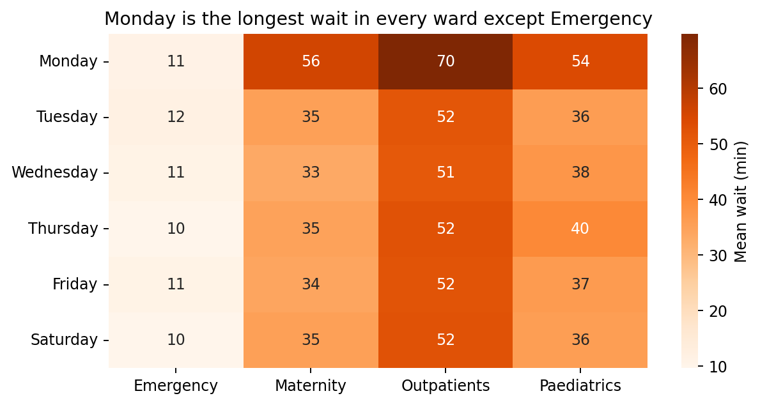

💡 Without reindex the days would be alphabetical, starting with Friday. annot=True writes each value in its square. fmt=".0f" means no decimal places.

🆘 *If you see* `KeyError in reindex or a blank row` → Check the spelling of the day names. They must match the weekday column exactly.

---
## Step 10 · Mini-project: Maya's one-page district report  *(~8 min)*
**Concept:** putting it all together, plt.savefig

📖 Friday's meeting. Maya has one page. Four charts, each with a title that states the finding. Then she saves it as a picture for the slides.

🎯 **Your task**
1. Create a 2 × 2 grid.
2. Fill all four charts.
3. Add an overall title with `fig.suptitle`.
4. Save the figure with `plt.savefig`, BEFORE `plt.show()`.

<details><summary>👀 Need the code? Click to reveal (try on your own first!)</summary>

```python
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))

axes[0, 0].plot(by_month.index, by_month.values, color="#D9533D", linewidth=2.5, marker="o")
axes[0, 0].set_title("Malaria peaks in July and August")
axes[0, 0].set_xticks(range(1, 13))
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylim(0)

axes[0, 1].barh(by_ward.index, by_ward.values, color="#2F79B5")
axes[0, 1].set_title("Outpatients carries the biggest load")
axes[0, 1].set_xlabel("Visits")

sns.boxplot(data=df, x="ward", y="wait_mins", color="#FFCB52", ax=axes[1, 0])
axes[1, 0].set_title("Emergency is seen fastest; Outpatients waits longest")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Wait (min)")

sns.heatmap(table, annot=True, fmt=".0f", cmap="Oranges", cbar=False, ax=axes[1, 1])
axes[1, 1].set_title("Mondays are the bottleneck")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("")

fig.suptitle("Community Health Clinic: 2025 at a glance", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("district_report.png", dpi=150)
plt.show()
```
</details>

In [ ]:
# Step 10: the one-page report


✅ **Expected chart**

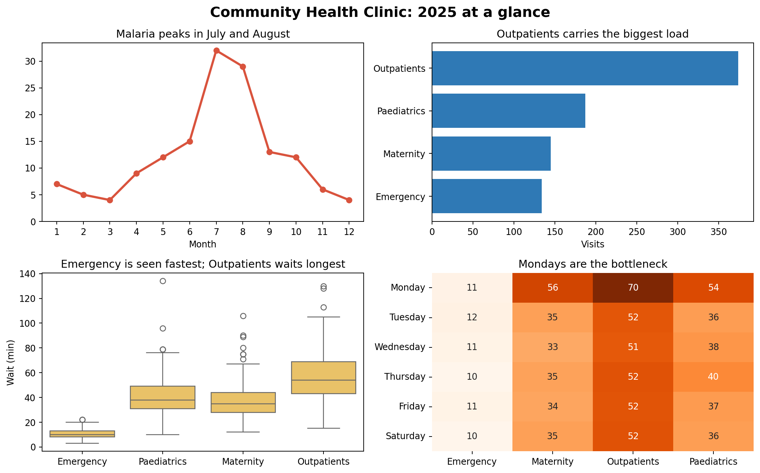

💡 Save before show: plt.show() clears the figure, so saving afterwards gives you a blank image. dpi sets how sharp the picture is.

🆘 *If you see* `A blank image file` → You called plt.savefig after plt.show(). Swap the two lines.

---
# 🌟 Finished early? Challenges
Optional extras for fast finishers.

### Challenge 1 · A pie chart (and why to be careful)
Draw a pie chart of `outcome` showing percentages. Then write one sentence: when would a bar chart be better?

In [ ]:
# Challenge 1


### Challenge 2 · Joint plot
Use `sns.jointplot` to show height against weight, with the distribution of each along the edges.

In [ ]:
# Challenge 2


### Challenge 3 · Small multiples
Use `sns.displot` with `col="ward"` to draw one histogram of `wait_mins` for each ward.

In [ ]:
# Challenge 3


---
## 🎉 Well done!
You chose charts from questions, built them in Matplotlib and Seaborn, and made a one-page report. **Save this notebook** (Ctrl + S), then commit it and `district_report.png` to GitHub.

Next: **Week2_Exercises_Visualisation.ipynb**.